# Exploration

The configured `djovak/embedic-large` checkpoint returned 401 Unauthorized from Hugging Face in this environment. This run uses the publicly accessible `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` checkpoint instead; its results should not be attributed to the original checkpoint.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sentence_transformers import SentenceTransformer

sys.path.insert(0, str(Path.cwd()))

from data import load_data, make_groups
from evaluation import evaluate, split_data

data = load_data("../data/processed/headlines.csv")
data["group"] = make_groups(data)
labels = sorted(data["label"].unique())
train_indices, test_indices = split_data(data)
train = data.iloc[train_indices]
test = data.iloc[test_indices]

train_sentences = train["headline"].tolist()
test_sentences = test["headline"].tolist()
print(f"Training rows: {len(train)}; test rows: {len(test)}")

/Users/jtakalai/python/propaganda-radar/regression/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1024 19:43:44.350000 33748 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Training rows: 323; test rows: 132


In [3]:
model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")

X_train = model.encode(
    train_sentences,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
)

X_test = model.encode(
    test_sentences,
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
)

print(f"Embedding shapes: train={X_train.shape}; test={X_test.shape}")

Batches: 100%|██████████| 5/5 [00:00<00:00, 12.63it/s]

Embedding shapes: train=(323, 384); test=(132, 384)


In [4]:
classifier = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42,
)
classifier.fit(X_train, train["label"])
predictions = classifier.predict(X_test)
metrics = evaluate(test["label"], predictions, labels)
report = metrics["report"]

transformer_summary = {
    "accuracy": accuracy_score(test["label"], predictions),
    "macro_precision": report["macro avg"]["precision"],
    "macro_recall": report["macro avg"]["recall"],
    "macro_f1": report["macro avg"]["f1-score"],
    "weighted_f1": report["weighted avg"]["f1-score"],
    "test_rows": len(test),
}
print(transformer_summary)
display(
    pd.DataFrame(report).T[
        ["precision", "recall", "f1-score", "support"]
    ].round(3)
)

{'accuracy': 0.5909090909090909, 'macro_precision': 0.42690134724033035, 'macro_recall': 0.5183190049387233, 'macro_f1': 0.4593387314439946, 'weighted_f1': 0.5828374841532736, 'test_rows': 132}


,precision,recall,f1-score,support
nothing,0.538,0.636,0.583,22.000
personality_cult,0.333,0.571,0.421,7.000
vilifying_eu,0.000,0.000,0.000,12.000
vilifying_neighbours,0.500,0.750,0.600,20.000
vilifying_opponents,0.763,0.634,0.692,71.000
accuracy,0.591,0.591,0.591,0.591
macro avg,0.427,0.518,0.459,132.000
weighted avg,0.593,0.591,0.583,132.000


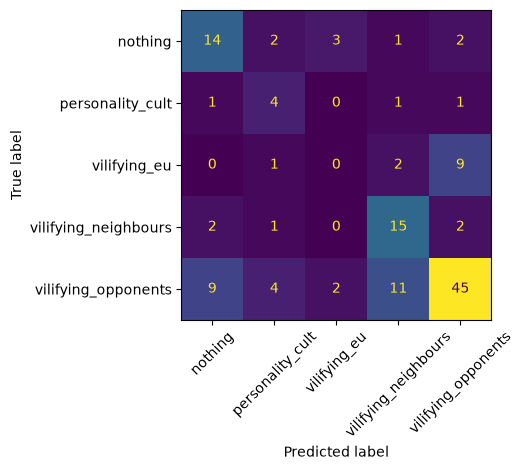

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=metrics["confusion_matrix"],
    display_labels=labels,
).plot(xticks_rotation=45, colorbar=False)
plt.tight_layout()
plt.show()